# Week 01: When was seasonal bread sold?

This notebook loads the course bakery sales data from the public URL specified in `AGENTS.md`. It identifies dates with sales of seasonal bread (product group 6), compares mean daily turnover in October and November, and uses Welch's unequal-variance t-test.

**Important:** a row is a day with an observed sales record. The source reports turnover, not units sold or profit.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

DATA_URL = (
    "https://raw.githubusercontent.com/opencampus-sh/"
    "intro-to-data-science-and-ml/main/data/bakery/"
    "umsatzdaten_gekuerzt.csv"
)

## 1. Load and check the source data

`Datum` is converted to a datetime before analysis. The row-count and key checks establish that the raw file loaded as expected.

In [2]:
sales = pd.read_csv(DATA_URL, parse_dates=["Datum"])

expected_columns = {"id", "Datum", "Warengruppe", "Umsatz"}
assert expected_columns.issubset(sales.columns), "The source is missing expected columns"
assert len(sales) == 9334, f"Unexpected row count: {len(sales)}"
assert sales[["Datum", "Warengruppe"]].duplicated().sum() == 0, "Date/product rows are duplicated"

print(f"Loaded {len(sales):,} sales rows")
print(f"Date range: {sales['Datum'].min().date()} to {sales['Datum'].max().date()}")
sales.head()

Loaded 9,334 sales rows
Date range: 2013-07-01 to 2018-07-31


,id,Datum,Warengruppe,Umsatz
0,1307011,2013-07-01,1,148.828353
1,1307021,2013-07-02,1,159.793757
2,1307031,2013-07-03,1,111.885594
3,1307041,2013-07-04,1,168.864941
4,1307051,2013-07-05,1,171.280754


## 2. Select the seasonal-bread sold days

Product group `6` represents seasonal bread. Because the source has a row only for a product's sales day, the table below is a list of observed sold days rather than a complete calendar.

In [3]:
seasonal_bread = sales.loc[sales["Warengruppe"] == 6].copy()

assert not seasonal_bread.empty, "No seasonal-bread rows were found"
assert seasonal_bread["Umsatz"].ge(0).all(), "Turnover cannot be negative"
assert seasonal_bread["Datum"].nunique() == len(seasonal_bread), "Each sold date should occur once"

sold_days = seasonal_bread.assign(
    Year=seasonal_bread["Datum"].dt.year,
    Month=seasonal_bread["Datum"].dt.month,
    Month_name=seasonal_bread["Datum"].dt.strftime("%B")
).loc[:, ["Datum", "Year", "Month", "Month_name", "Umsatz"]].sort_values("Datum").reset_index(drop=True)

print(f"Seasonal bread has {len(seasonal_bread)} sold-day rows")
print(f"Date range: {seasonal_bread['Datum'].min().date()} to {seasonal_bread['Datum'].max().date()}")
sold_days

Seasonal bread has 292 sold-day rows
Date range: 2013-10-24 to 2017-12-27


,Datum,Year,Month,Month_name,Umsatz
0,2013-10-24,2013,10,October,41.813038
1,2013-10-25,2013,10,October,16.410876
2,2013-10-26,2013,10,October,18.574458
3,2013-10-27,2013,10,October,24.640084
4,2013-10-29,2013,10,October,43.515366
...,...,...,...,...,...
287,2017-12-21,2017,12,December,87.471228
288,2017-12-22,2017,12,December,71.911652
289,2017-12-23,2017,12,December,84.062223
290,2017-12-24,2017,12,December,60.981969


The table contains every observed seasonal-bread sales date in the past-years source. The summary below shows how many sold days and how much turnover occurred in each month.

In [4]:
sold_month_summary = (
    sold_days.groupby(["Year", "Month_name", "Month"])
    .agg(Sold_days=("Datum", "count"), Turnover=("Umsatz", "sum"))
    .reset_index()
    .sort_values(["Year", "Month"])
    .drop(columns="Month")
)

sold_month_summary

,Year,Month_name,Sold_days,Turnover
2,2013,October,7,200.650385
1,2013,November,30,1948.425359
0,2013,December,27,1946.137941
4,2014,January,1,35.620197
6,2014,October,5,184.346965
5,2014,November,29,1565.707663
3,2014,December,27,2177.416093
8,2015,January,5,149.282295
9,2015,November,24,1484.053840
7,2015,December,29,2304.658687


## 3. Compare October and November

The two samples contain recorded daily turnover values across the available years. Each mean is an average over sold days in that month, not an average over every calendar day or a unit-sales forecast.

In [5]:
october = seasonal_bread.loc[seasonal_bread["Datum"].dt.month == 10, "Umsatz"]
november = seasonal_bread.loc[seasonal_bread["Datum"].dt.month == 11, "Umsatz"]

assert len(october) > 1, "October needs at least two observations"
assert len(november) > 1, "November needs at least two observations"

comparison = pd.DataFrame({
    "Month": ["October", "November"],
    "Observed sold days": [len(october), len(november)],
    "Mean daily turnover": [october.mean(), november.mean()],
    "Median daily turnover": [october.median(), november.median()],
    "Standard deviation": [october.std(ddof=1), november.std(ddof=1)],
})

comparison

,Month,Observed sold days,Mean daily turnover,Median daily turnover,Standard deviation
0,October,13,34.587276,38.096538,14.141642
1,November,140,58.837276,52.057188,29.537659


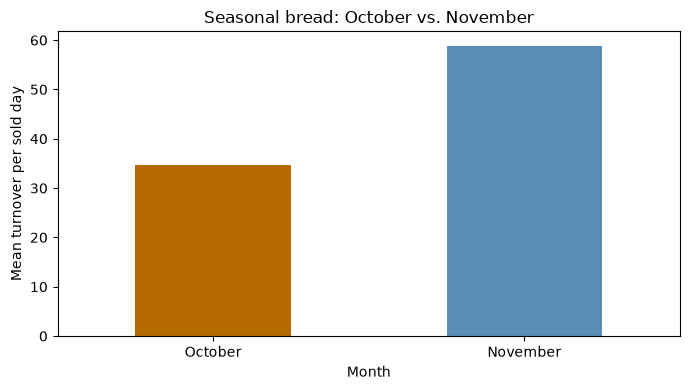

In [6]:
comparison.plot(
    x="Month", y="Mean daily turnover", kind="bar", legend=False,
    figsize=(7, 4), color=["#B56A00", "#5B8DB8"]
)
plt.ylabel("Mean turnover per sold day")
plt.title("Seasonal bread: October vs. November")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## 4. Welch's unequal-variance t-test

$H_0$: mean October turnover equals mean November turnover.

$H_1$: mean turnover differs between October and November.

Welch's test does not assume equal variances. We use a two-sided test and $\alpha = 0.05$.

In [7]:
welch = stats.ttest_ind(october, november, equal_var=False)

test_result = pd.DataFrame({
    "Statistic": [welch.statistic],
    "Degrees of freedom": [welch.df],
    "p-value": [welch.pvalue],
})

alpha = 0.05
if welch.pvalue < alpha:
    conclusion = "Reject H0: mean daily turnover differs significantly between October and November at alpha = 0.05."
else:
    conclusion = "Do not reject H0: the mean difference is not significant at alpha = 0.05."

test_result

,Statistic,Degrees of freedom,p-value
0,-5.215899,23.360874,0.000026


In [8]:
print(conclusion)
print(f"Observed difference (October - November): {october.mean() - november.mean():.6f} turnover units")

Reject H0: mean daily turnover differs significantly between October and November at alpha = 0.05.
Observed difference (October - November): -24.250000 turnover units


## 5. Interpretation and limits

- October has far fewer sold-day observations than November, so its mean is based on a much smaller sample.
- The test pools calendar days and is descriptive; the test can be affected by repeated observations and by the sparse October data.
- A significant result would show a difference in recorded turnover, not that customers prefer one month or that starting in October is profitable.
- The full sold-day table and month summary let us inspect exactly which years and dates contribute to the result.

In [ ]:
Results:

October: 13 sold-day observations, mean daily turnover 34.5873
November: 140 sold-day observations, mean daily turnover 58.8373
Welch’s t-test: t = -5.216, p = 0.0000261
Conclusion: mean turnover differs significantly at
a
l
p
h
a
=
0.05
alpha=0.05